# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr")#"/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed_filtered.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

# Module analysis

In [3]:
adata = sdata["table"]



In [4]:
adata

AnnData object with n_obs × n_vars = 9185 × 4240
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes', 'n_counts', 'leiden', 'cell_type', 'urna_contribution_score', 'urna_source_score'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_id', 'n_cells'
    uns: 'cell_type_colors', 'dendrogram_leiden', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'spatialdata_attrs', 'umap'
    obsm: 'X_pca', 'X_umap', 'factors_cell_loadings', 'spatial'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'connectivities', 'distances'

In [99]:
import pandas as pd
import numpy as np
import scanpy as sc
from scipy.stats import mannwhitneyu
from tqdm import tqdm

# Set your distance threshold (you can tune this)
DISTANCE_THRESHOLD = 10.0

# Cell-level data
cell_df = adata.obs[['cell_type']].copy()
cell_df['cell_id']=adata.obs.index
cell_df['has_proximal_urna'] = False

# uRNA data
urna_obs = sdata['source_score'].obs.copy()

# Filter uRNAs within distance threshold
proximal_urna = urna_obs[urna_obs['distance'] <= DISTANCE_THRESHOLD]

# Map: cell_id -> list of uRNA genes nearby
from collections import defaultdict
cell_to_urna_genes = defaultdict(list)

# Add tqdm with total rows for progress tracking
for idx, row in tqdm(proximal_urna.iterrows(), total=len(proximal_urna), desc="Mapping uRNAs to closest cells"):
    cell_to_urna_genes[row['closest_cell']].append(row['gene'])



Mapping uRNAs to closest cells: 100%|████████████████████████████████████████| 988270/988270 [00:37<00:00, 26092.90it/s]


In [100]:
# Add to cell_df: list of proximal uRNAs per cell
cell_df['proximal_urna_genes'] = cell_df['cell_id'].map(cell_to_urna_genes).fillna('').apply(lambda x: x if isinstance(x, list) else [])

In [101]:
# Flatten for comparison: explode by (cell_type, urna_gene)
rows = []
for _, row in tqdm(cell_df.iterrows(), total=len(cell_df), desc="Building cell-urna pairs"):
    for gene in set(row['proximal_urna_genes']):
        rows.append({
            'cell_id': row['cell_id'],
            'cell_type': row['cell_type'],
            'urna_gene': gene,
            'has_proximal': True
        })

proximal_df = pd.DataFrame(rows)

# Merge with all cells to include those with no proximal uRNA
all_combos = cell_df[['cell_id', 'cell_type']].merge(
    proximal_df,
    on=['cell_id', 'cell_type'],
    how='left'
)
all_combos['has_proximal'] = all_combos['has_proximal'].fillna(False)
all_combos['urna_gene'] = all_combos['urna_gene'].fillna('none')


Building cell-urna pairs: 100%|███████████████████████████████████████████████████| 9185/9185 [00:02<00:00, 3172.44it/s]


In [144]:
xrna_metadata=sdata['xrna_metadata'].var

In [167]:
selgenes=xrna_metadata[xrna_metadata['logfoldratio_over_noise']>8].index

In [168]:
all_combos_filt.shape

(3614, 4)

In [169]:
all_combos_filt=all_combos[all_combos['urna_gene'].isin(selgenes)]

In [170]:
all_combos_filt.shape

(81919, 4)

# This chunk checks overall differences based on the presence/absence for cell types

In [164]:
# Now test expression differences for each (cell_type, urna_gene) pair
results = []

for (cell_type, urna_gene), group in tqdm(all_combos_filt.groupby(['cell_type', 'urna_gene']), 
                                          total=all_combos_filt.groupby(['cell_type', 'urna_gene']).ngroups,
                                          desc="Testing expression vs proximity"):
    if urna_gene == 'none':
        continue

    # Check expression of the same gene in these cells (could change target gene)
    if urna_gene not in adata.var_names:
        continue  # skip if uRNA gene not present in cell expression data

    adatasub=adata[adata.obs['cell_type']==cell_type,:]
    
    cells_with = group[group['has_proximal']]['cell_id'].values
    cells_without=adatasub.obs.index[~adatasub.obs.index.isin(cells_with)]
    
    expr_with = adatasub[cells_with, urna_gene].layers['raw'].A.flatten() if hasattr(adata.X, 'A') else adatasub[cells_with, urna_gene].layers['raw'].flatten()
    expr_without = adatasub[cells_without, urna_gene].layers['raw'].A.flatten() if hasattr(adata.X, 'A') else adatasub[cells_without, urna_gene].layers['raw'].flatten()

    if len(expr_with) < 5 or len(expr_without) < 5:
        continue  # too few cells for statistical test

    stat, pval = mannwhitneyu(expr_with, expr_without, alternative='two-sided')

    results.append({
        'cell_type': cell_type,
        'urna_gene': urna_gene,
        'n_with': len(expr_with),
        'n_without': len(expr_without),
        'mean_expr_with': np.mean(expr_with),
        'mean_expr_without': np.mean(expr_without),
        'p_value': pval
    })


Testing expression vs proximity: 100%|██████████████████████████████████████████████████| 16/16 [00:03<00:00,  4.74it/s]


# This chunk checks overall differences for every gene

In [171]:
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd
from tqdm import tqdm

results = []

grouped = all_combos_filt.groupby(['cell_type', 'urna_gene'])

for (cell_type, urna_gene), group in tqdm(grouped, total=grouped.ngroups,
                                          desc="Testing all genes vs uRNA proximity"):

    if urna_gene == 'none':
        continue

    adatasub = adata[adata.obs['cell_type'] == cell_type, :].copy()
    
    # Set X = raw for filtering
    adatasub.X = adatasub.layers['raw']
    sc.pp.filter_genes(adatasub, min_cells=50)
    adatasub.layers['raw'] = adatasub.X

    if adatasub.n_vars < 1:
        continue

    # Create expression DataFrame from raw layer (cells x genes)
    expr_matrix = adatasub.layers['raw']
    if hasattr(expr_matrix, 'A'):  # sparse
        expr_matrix = expr_matrix.A
    expr_df = pd.DataFrame(expr_matrix, index=adatasub.obs_names, columns=adatasub.var_names)

    # Identify cells with and without proximity
    cells_with = group[group['has_proximal']]['cell_id'].values
    cells_without = adatasub.obs.index[~adatasub.obs.index.isin(cells_with)].values

    if len(cells_with) < 20 or len(cells_without) < 20:
        continue

    # Subset once instead of per gene
    expr_with = expr_df.loc[cells_with]
    expr_without = expr_df.loc[cells_without]

    for gene in expr_df.columns:
        vals_with = expr_with[gene].values
        vals_without = expr_without[gene].values

        if len(vals_with) < 5 or len(vals_without) < 5:
            continue

        stat, pval = mannwhitneyu(vals_with, vals_without, alternative='two-sided')

        results.append({
            'cell_type': cell_type,
            'urna_gene': urna_gene,
            'test_gene': gene,
            'n_with': len(vals_with),
            'n_without': len(vals_without),
            'mean_expr_with': np.mean(vals_with),
            'mean_expr_without': np.mean(vals_without),
            'p_value': pval
        })


Testing all genes vs uRNA proximity: 100%|████████████████████████████████████████████| 551/551 [18:23<00:00,  2.00s/it]


In [364]:
# Compile results
results_df = pd.DataFrame(results)
results_df['p_adj'] = results_df['p_value'] * len(results_df)  # Bonferroni correction (optional)
results_df = results_df.sort_values('p_value')

In [365]:
results_df['-log_p_adj']=-np.log(results_df['p_adj'])
results_df['logfoldratio']=np.log2(results_df['mean_expr_with']/results_df['mean_expr_without'])
results_df=results_df[results_df['urna_gene']!=results_df['test_gene']]

In [366]:
# Show top results
results_df.head(5)

,cell_type,urna_gene,test_gene,n_with,n_without,mean_expr_with,mean_expr_without,p_value,p_adj,-log_p_adj,logfoldratio
295,Astrocytes,Adcy1,Camk2a,444,861,5.603604,2.355401,1.867720e-46,1.564092e-40,91.656098,1.250382
29347,Astrocytes,Hpcal4,Camk2a,299,1006,6.682274,2.502982,3.619521e-43,3.031110e-37,84.086720,1.416691
690848,Oligodendrocytes,Atp1b2,Slc6a11,388,874,1.095361,0.143021,7.832163e-39,6.558919e-33,74.104482,2.937111
712834,Oligodendrocytes,Kcnab2,Camk2a,161,1101,3.366460,0.896458,2.809560e-36,2.352821e-30,68.221938,1.908925
53557,Astrocytes,Nsmf,Camk2a,914,391,4.204595,1.721228,2.924822e-36,2.449346e-30,68.181732,1.288529


In [196]:
results_filt=results_df[results_df['p_adj']<0.05]

<Axes: xlabel='-log_p_adj', ylabel='cell_type'>

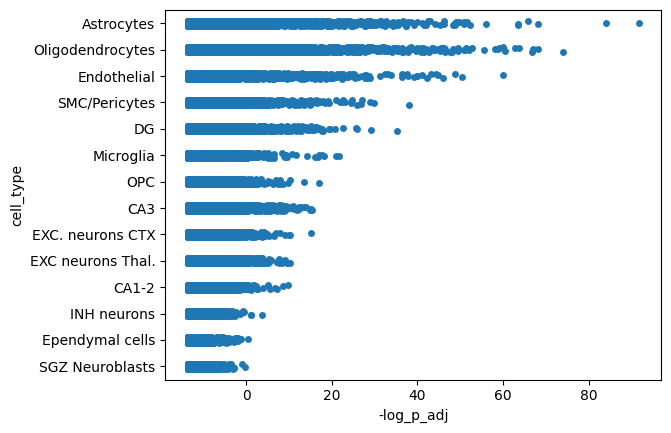

In [188]:
sns.stripplot(data=results_df,y='cell_type',x='-log_p_adj',s=5)

<Axes: xlabel='n_with', ylabel='cell_type'>

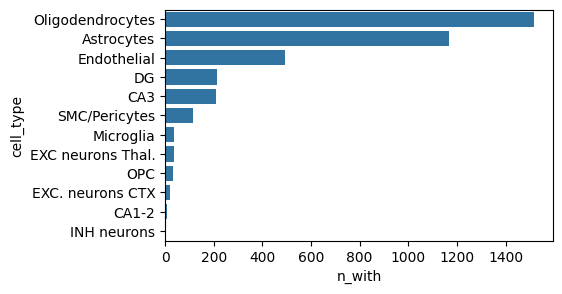

In [210]:
ct_counts=results_filt.groupby('cell_type').count()
ct_counts=ct_counts.sort_values('test_gene',ascending=False)
plt.figure(figsize=(5,3))
sns.barplot(y=ct_counts.index,x=ct_counts['n_with'])

<Axes: xlabel='n_with', ylabel='urna_gene'>

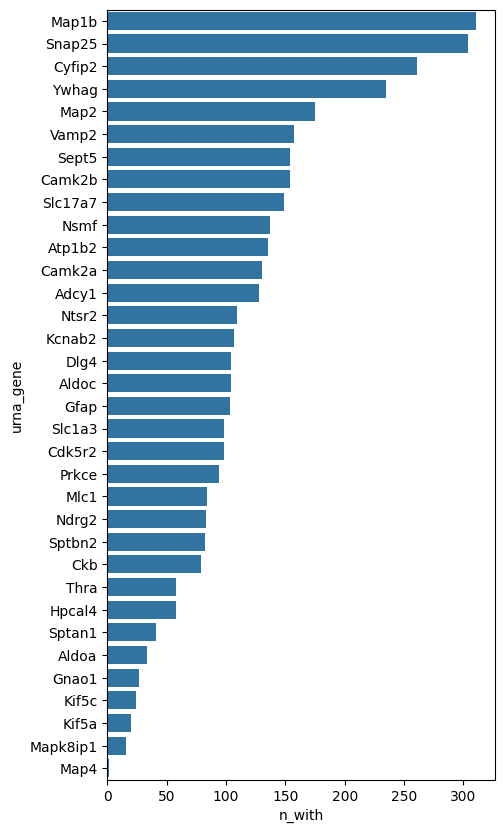

In [212]:
ct_counts=results_filt.groupby('urna_gene').count()
ct_counts=ct_counts.sort_values('test_gene',ascending=False)
plt.figure(figsize=(5,10))
sns.barplot(y=ct_counts.index,x=ct_counts['n_with'])

<Axes: xlabel='n_with', ylabel='test_gene'>

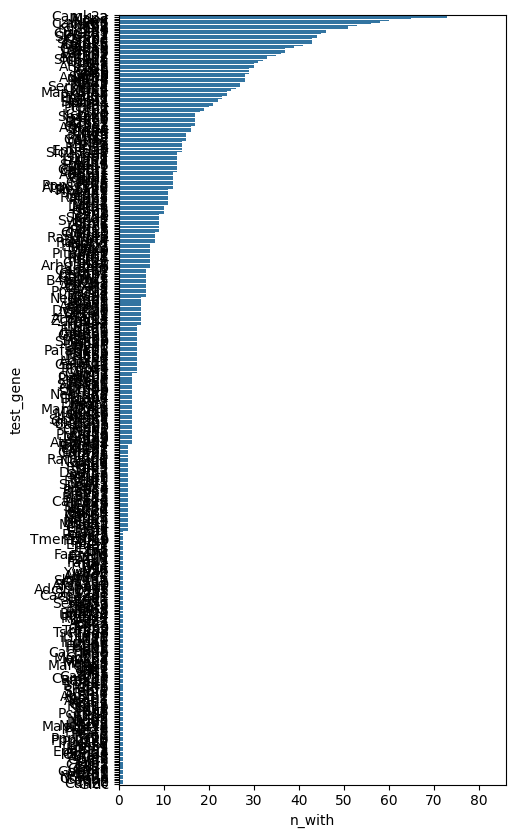

In [213]:
ct_counts=results_filt.groupby('test_gene').count()
ct_counts=ct_counts.sort_values('urna_gene',ascending=False)
plt.figure(figsize=(5,10))
sns.barplot(y=ct_counts.index,x=ct_counts['n_with'])

# Plot based on cell type

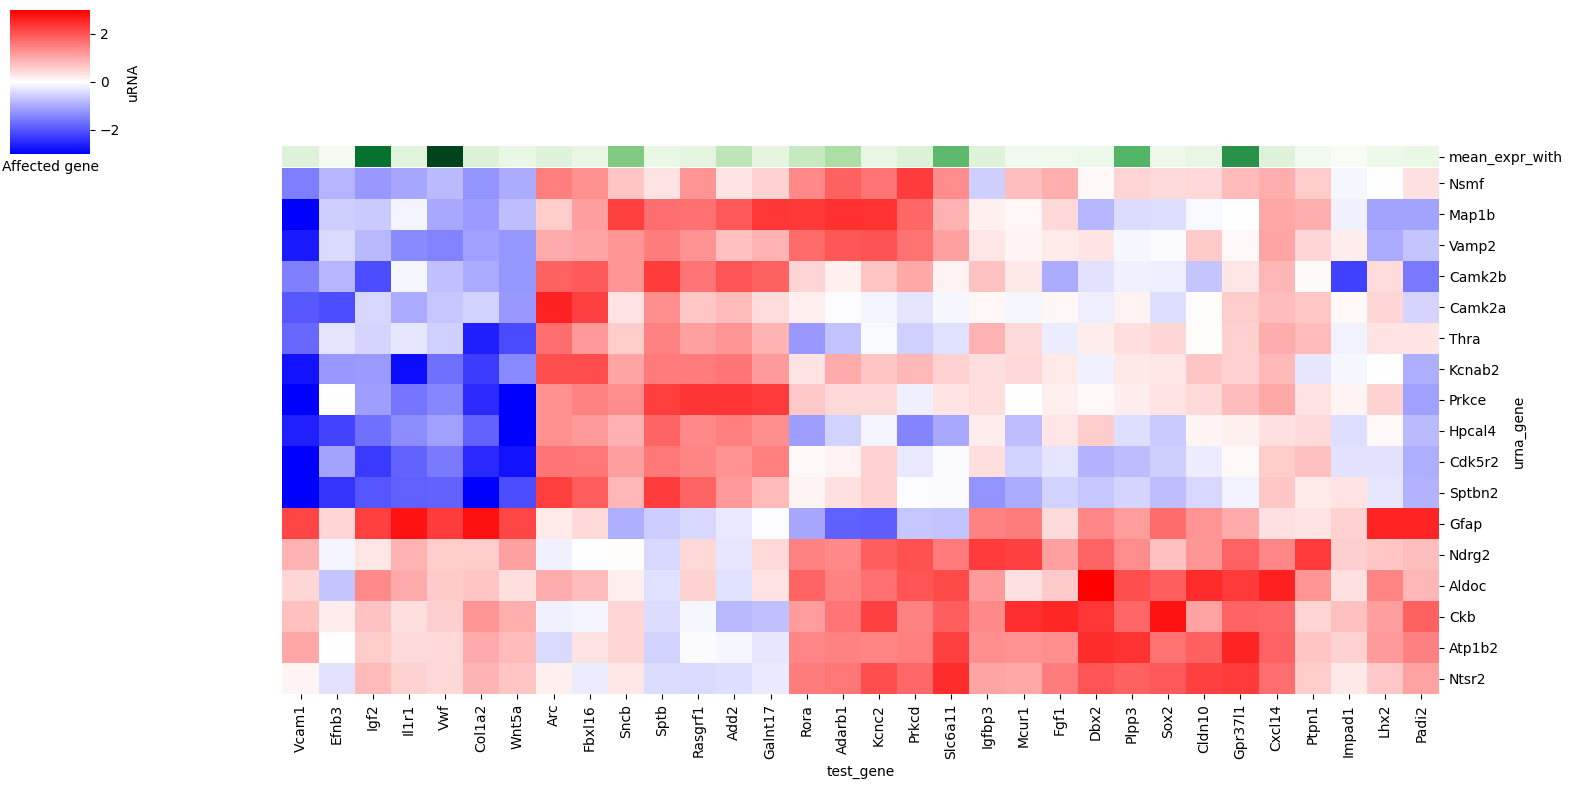

In [368]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ct = 'Endothelial'
results_filt = results_df[results_df['cell_type'] == ct]

# Pivot the data
output = results_filt.pivot(index='urna_gene', columns='test_gene', values='logfoldratio')
output[np.isinf(output)] = 0
output = output.fillna(0)

# Filter genes with strong effects
output_filt = output.loc[:, np.max(np.abs(output), axis=0) > 2.2]
output_filt = output_filt.loc[np.max(np.abs(output), axis=1) > 2.2, :]

# Prepare mean expression values
# Get test_genes (columns) that are in output_filt
selected_genes = output_filt.columns
mean_expr = results_filt.drop_duplicates(subset='test_gene').set_index('test_gene')['mean_expr_with']
mean_expr = mean_expr.reindex(selected_genes)

# Normalize the mean expression for color mapping
norm = plt.Normalize(mean_expr.min(), mean_expr.max())
cmap = plt.cm.Greens
col_colors = pd.DataFrame({
    'mean_expr_with': [cmap(norm(v)) for v in mean_expr.values]
}, index=selected_genes)

# Plot
g = sns.clustermap(
    output_filt,
    cmap='bwr',
    row_cluster=True,
    col_cluster=True,
    xticklabels=True,
    yticklabels=True,
    figsize=(16, 8),
    vmax=3, vmin=-3,
    col_colors=col_colors
)

# Hide dendrograms if desired
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)

# Add colorbar for the mean_expr_with annotation
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=cmap(norm(val)), label=f"{val:.1f}") for val in np.linspace(mean_expr.min(), mean_expr.max(), 4)]
g.ax_col_dendrogram.legend(
    handles=legend_elements,
    title='mean_expr_with',
    loc='center',
    bbox_to_anchor=(0.5, 1.2),
    ncol=4
)

plt.xlabel('Affected gene')
plt.ylabel('uRNA')
#plt.savefig(os.path.join(saving_path,'endo_expression_depend_urna.pdf'))
plt.show()


In [ ]:
tran=sdata['transcripts'][['x','y','gene','extracellular']].compute()
tran1=tran[tran['gene']=='Gfap']
tran2=tran1[tran1['extracellular']==True]
tran3=tran1[tran1['extracellular']!=True]
tran3=tran1[tran1['extracellular']!=True]

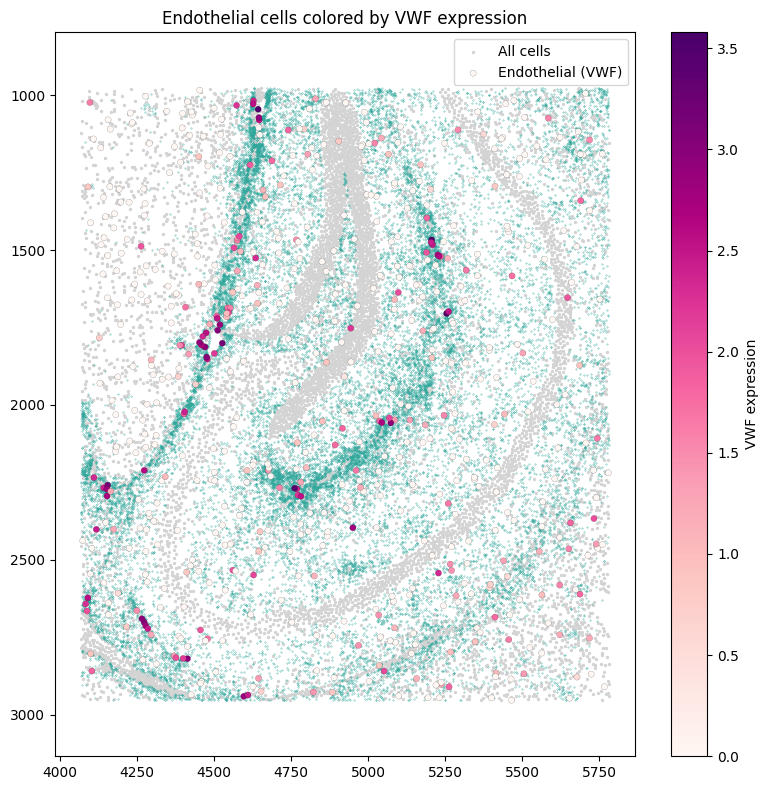

In [367]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Extract spatial coordinates
coords = adata.obsm['spatial']
x = coords[:, 0]
y = coords[:, 1]

# Identify endothelial cells
is_endothelial = adata.obs['cell_type'] == 'Endothelial'
endothelial_coords = coords[is_endothelial]

# Get expression values for VWF (only for endothelial)
vwf_expr = adata[is_endothelial, 'Vwf'].X
# If X is sparse, convert to dense
if not isinstance(vwf_expr, np.ndarray):
    vwf_expr = vwf_expr.toarray().flatten()

# Plot
plt.figure(figsize=(8, 8))

plt.scatter(x, y, c='lightgray', s=2, label='All cells')  # background

plt.scatter(tran2['x'],tran2['y'],s=0.07,color='#32a89d')
#plt.scatter(tran3['x'],tran3['y'],s=0.04,color='#3258a8')

sc = plt.scatter(
    endothelial_coords[:, 0], endothelial_coords[:, 1],
    c=vwf_expr, cmap='RdPu', s=20, label='Endothelial (VWF)', edgecolor='k', linewidth=0.1)


plt.axis('equal')
plt.gca().invert_yaxis()  # Optional: depends on your data orientation
plt.title('Endothelial cells colored by VWF expression')
plt.colorbar(sc, label='VWF expression')
plt.legend()
plt.tight_layout()

#plt.savefig(os.path.join(saving_path,'VWF_endo_depend_on_Gfap_scatter.pdf'))

plt.show()


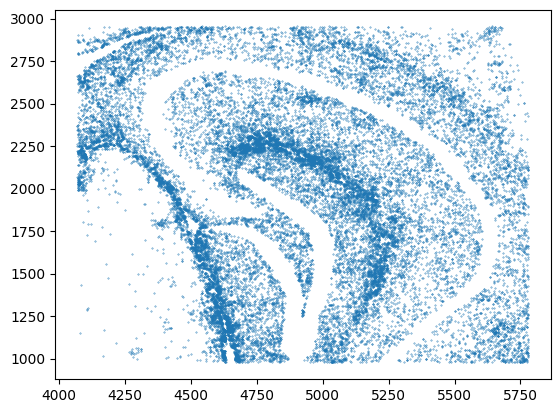

In [351]:
plt.scatter(tran2['x'],tran2['y'],s=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

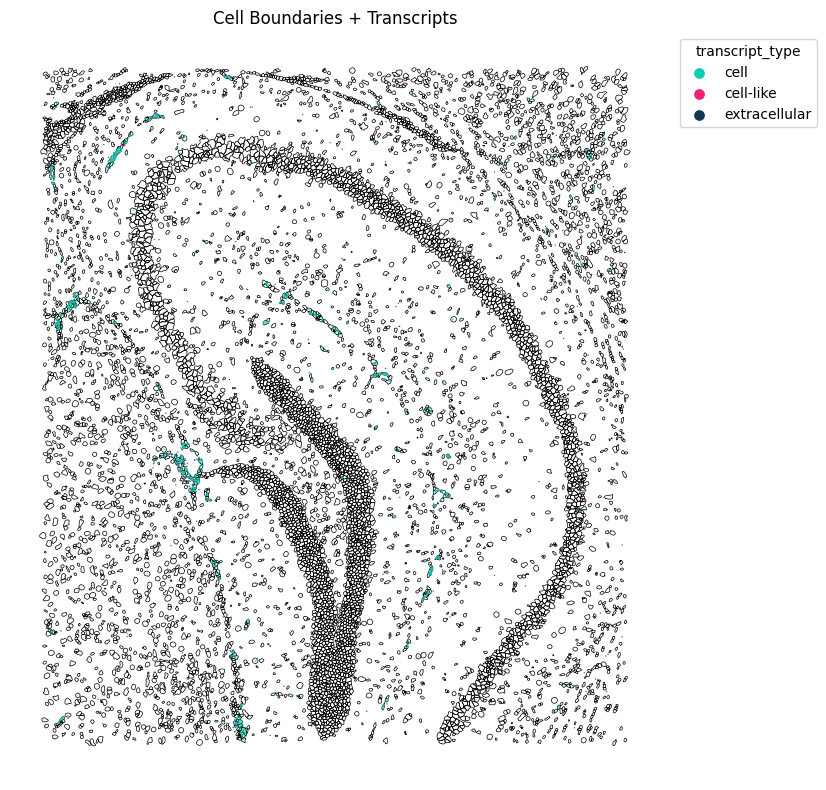

In [325]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Vwf'])

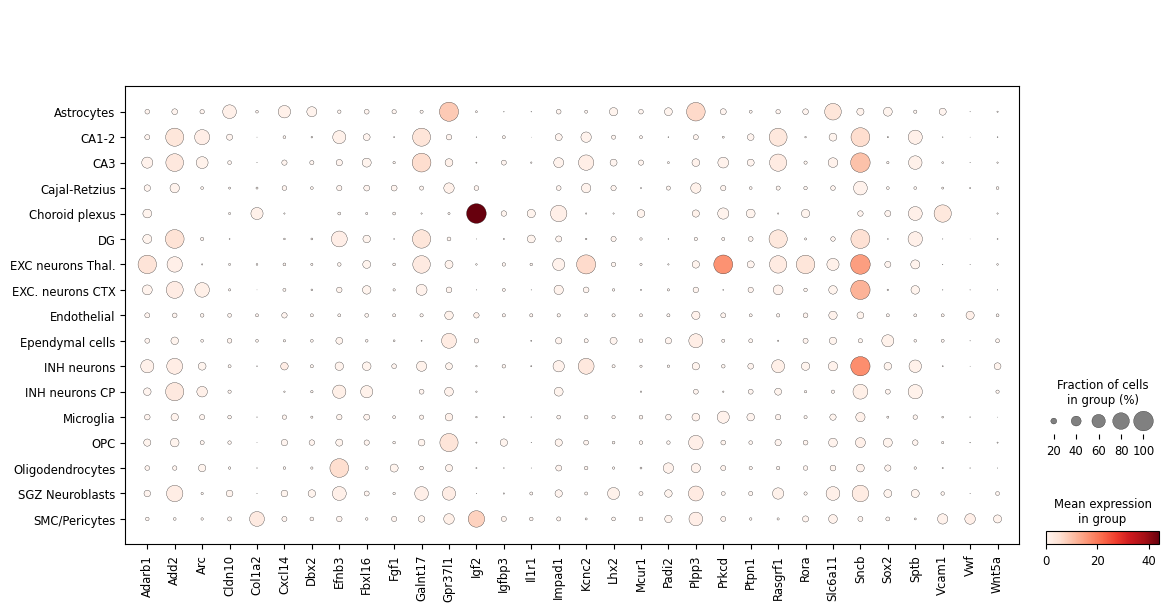

In [324]:
sc.pl.dotplot(adata,output_filt.columns,groupby='cell_type')

test_gene,Adarb1,Agt,Amy1,Aqp4,Axin1,Calb2,Chrna4,Chrnb2,Cldn10,Cpne4,...,Sirt4,Slc12a5,Slc17a6,Slc6a11,Syngr3,Thbs4,Tlcd1,Tmem173,Zcchc12,Zic1
urna_gene,,,,,,,,,,,,,,,,,,,,,
Adcy1,1.938179,-0.093789,-1.498179,0.643177,0.224287,1.965929,1.066320,1.878197,0.341598,0.656639,...,0.066320,1.256709,2.153057,1.020015,1.133705,-2.286674,0.823749,-1.941785,1.771282,1.583546
Aldoc,0.362737,2.530447,-0.495716,2.146650,0.117491,-0.626256,0.018946,0.763435,2.148309,0.199563,...,0.130850,-0.389138,0.043943,2.068367,0.114171,0.881004,2.667298,0.029868,0.374250,0.494365
Atp1b2,1.529129,3.061394,-0.413386,2.478238,0.547086,2.014035,1.025726,1.368613,2.438363,0.350547,...,0.443656,0.720197,1.812682,2.937111,0.393969,0.517221,1.756539,-1.134232,1.721774,1.709542
Camk2b,1.690755,-0.132248,-3.266104,-0.037611,-2.869213,2.143287,1.548292,2.708370,-0.269751,1.985210,...,-1.734912,2.220541,2.225047,0.625752,1.463942,-1.657709,0.535177,-0.798824,2.222102,1.855474
Cdk5r2,1.648256,0.582008,-1.258211,-0.424492,0.181855,1.471890,1.023888,1.341617,0.028410,0.982951,...,-0.900507,1.708385,2.110625,0.462709,1.478754,-1.965917,0.211001,-2.749198,1.987768,1.804852
Cyfip2,1.856258,0.857153,-0.203876,-0.307844,0.419748,2.354384,2.057452,2.042846,0.237001,1.014695,...,0.015437,1.357666,2.167256,0.651538,1.725735,-1.799369,0.801977,-0.394207,2.205333,1.968185
Gfap,-2.303223,0.258080,0.093610,1.347758,0.195489,-1.829999,-2.276682,-2.090815,0.831505,-2.732361,...,0.575067,-1.884364,-2.726659,-0.291565,-2.372228,1.583785,0.442617,0.878811,-2.446959,-2.103306
Kcnab2,1.902266,0.658205,-1.908142,0.451754,0.743935,1.637905,1.208085,1.597832,0.529756,1.302376,...,-0.133209,1.381364,2.075951,0.603757,1.288255,-0.795513,-1.033673,-1.576815,1.958106,1.696606
Map1b,1.966938,1.408007,-0.010169,0.101645,-0.549591,1.778061,1.392694,2.078794,0.578337,0.807731,...,-0.127526,1.430403,2.037213,0.773888,1.158228,-2.022344,-0.104806,-0.924234,2.117586,2.065119


# Plot based on urna

In [369]:
ct='Camk2b'
results_filt=results_df[results_df['urna_gene']==ct]
output = results_filt.pivot(index='cell_type', columns='test_gene', values='logfoldratio')
output[np.isinf(output)] = 0
output=output.fillna(0)
output_filt=output.loc[:,np.max(np.abs(output),axis=0)>2.2]
output_filt=output_filt.loc[np.max(np.abs(output),axis=1)>2.2,:]

<Figure size 1600x400 with 0 Axes>

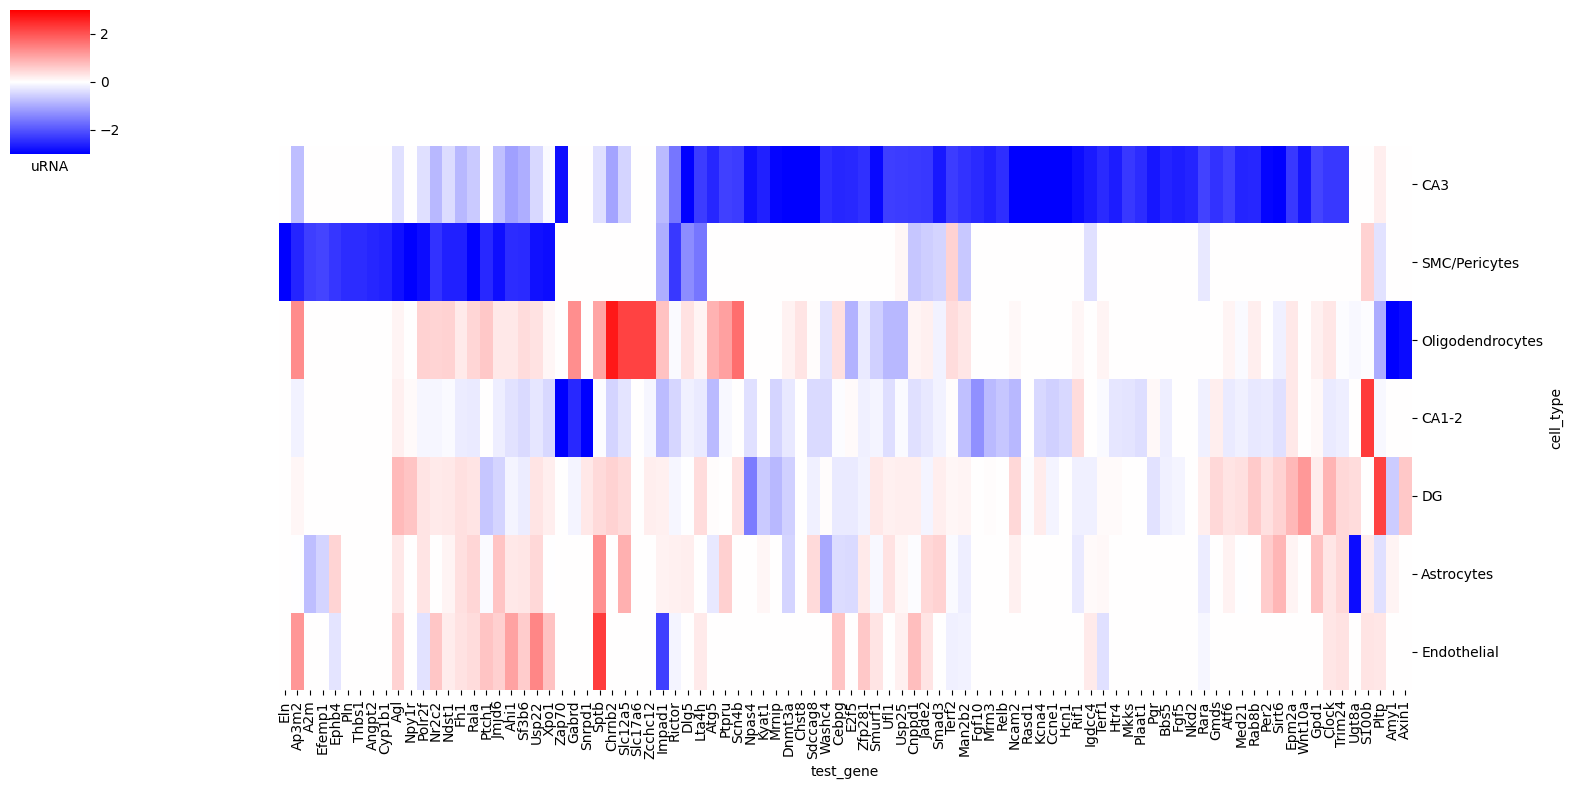

In [370]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16,4))
# Cluster the data
g = sns.clustermap(
    output_filt,
    cmap='bwr',
    row_cluster=True,
    col_cluster=True,
    xticklabels=True,
    yticklabels=True, figsize=(16,8), vmax=3, vmin=-3,
)

# Hide dendrogram axes (trees)
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
plt.xlabel('Affected gene')
plt.xlabel('uRNA')

plt.show()


In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_volcano_per_celltype(results_df, selected_urna_gene, pval_thresh=0.05, logfc_thresh=0.5, top_n=5):
    """
    Plot volcano plots per cell type for a selected uRNA gene, with top N genes labeled.

    Parameters:
        results_df (pd.DataFrame): Must contain ['cell_type', 'urna_gene', 'test_gene', 'mean_expr_with', 'mean_expr_without', 'p_value']
        selected_urna_gene (str): The uRNA gene to filter by.
        pval_thresh (float): Significance threshold for coloring.
        logfc_thresh (float): Threshold for log2 fold change coloring.
        top_n (int): Number of most significant genes to label per cell type.
    """
    
    df = results_df.copy()
    df = df[df['urna_gene'] == selected_urna_gene].copy()

    if df.empty:
        print(f"No data found for uRNA gene '{selected_urna_gene}'")
        return

    df['log2FC'] = np.log2((df['mean_expr_with'] + 1e-6) / (df['mean_expr_without'] + 1e-6))
    df['-log10(pval)'] = -np.log10(df['p_value'] + 1e-300)  # prevent -inf
    df['significant'] = (df['p_value'] < pval_thresh) & (abs(df['log2FC']) > logfc_thresh)

    cell_types = sorted(df['cell_type'].unique())
    ncols = 3
    nrows = int(np.ceil(len(cell_types) / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows), constrained_layout=True)
    axes = axes.flatten()

    for i, cell_type in enumerate(cell_types):
        ax = axes[i]
        sub = df[df['cell_type'] == cell_type]

        # Scatter plot
        sns.scatterplot(data=sub, x='log2FC', y='-log10(pval)', hue='significant',
                        palette={True: 'crimson', False: 'gray'}, ax=ax, legend=False, s=20)

        # Threshold lines
        ax.axhline(-np.log10(pval_thresh), color='blue', linestyle='--', linewidth=0.8)
        ax.axvline(logfc_thresh, color='blue', linestyle='--', linewidth=0.8)
        ax.axvline(-logfc_thresh, color='blue', linestyle='--', linewidth=0.8)

        # Label top N most significant genes
        top_genes = sub.nsmallest(top_n, 'p_value')
        for _, row in top_genes.iterrows():
            ax.text(row['log2FC'], row['-log10(pval)'], row['test_gene'],
                    fontsize=8, ha='right', va='bottom', color='black')

        ax.set_title(f"Cell type: {cell_type}")
        ax.set_xlabel("log2(Fold Change)")
        ax.set_ylabel("-log10(p-value)")

    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(f"Volcano plots for uRNA: {selected_urna_gene}", fontsize=16)
    plt.show()


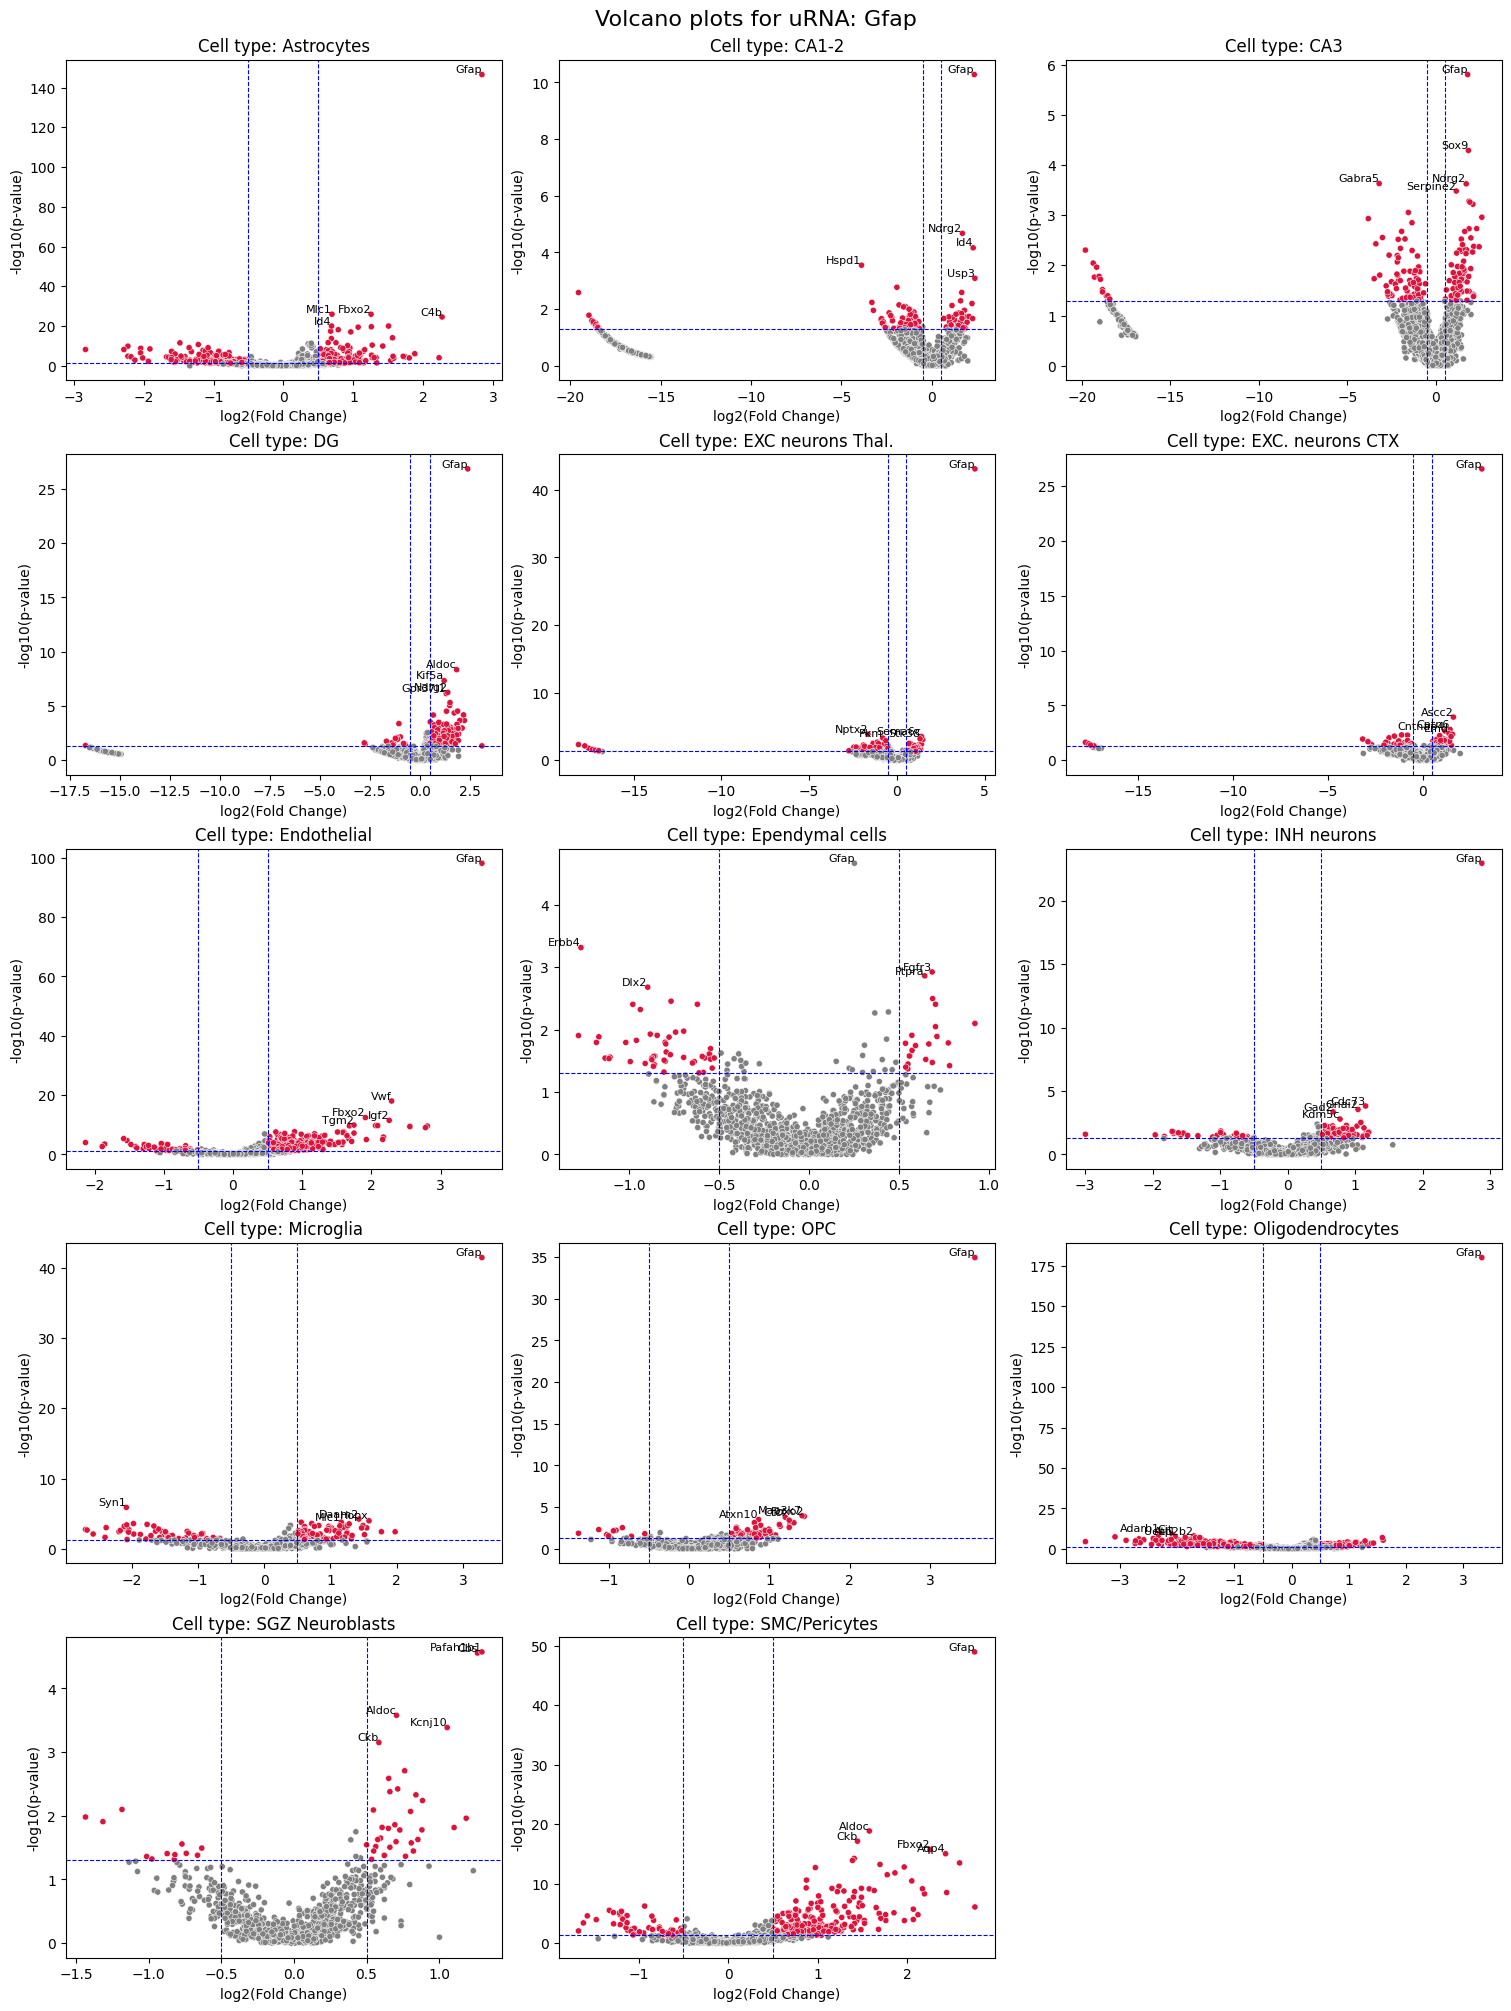

In [137]:
# Assuming results is already a DataFrame or converted from list of dicts
results_df = pd.DataFrame(results)

# Plot volcano plots for a specific uRNA gene
plot_volcano_per_celltype(results_df, selected_urna_gene='Gfap')
